# Experiment 3: regularized CatBoost and neural blending

This experiment compares CatBoost with the RF baseline and the existing RF–fine-tuned-MLP hybrid on **five spatial folds × three matched samples**, using **25 Amsterdam labels/class**.

The new hybrid averages a 50/50 Madrid/Amsterdam CatBoost blend with the existing fine-tuned MLP:

```text
P(new hybrid) = 0.25 × P(Madrid CatBoost)
              + 0.25 × P(Amsterdam CatBoost)
              + 0.50 × P(fine-tuned MLP)
```

The [implementation](../../scripts/catboost_experiment.py) contains all CatBoost training, nested selection, export, reload and verification functions. This notebook verifies and inspects saved artifacts by default; set `RETRAIN = True` to retrain. Prerequisites: preprocessed city tables, baseline memberships and `data/torch_transfer/` artifacts.

```bash
uv sync --locked --extra boosting --extra deep-learning
uv run --extra boosting --extra deep-learning --with jupyter jupyter lab
```

All scores are development scores on previously examined folds; no independent competition test is available.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'pyproject.toml').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the repository.')
sys.path.insert(0, str(ROOT))
import inspect
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scripts.catboost_experiment import CONFIG, METRICS, OUT, run, verify, select_target, predict_example
RETRAIN = False
if RETRAIN:
    run()
verify()

Verified 90 outer runs, 467,856 probability rows, 270 inner scores, 15 selections/budgets and exported inference.


## 1. Source training and fixed candidate grid

Madrid source training uses the original Madrid labels, matching the RF source task (first boundary 1960). The saved neural model used harmonized Madrid labels (first boundary 1945). These source-label procedures differ and remain explicit.

Source depth is fixed at 4. Madrid fold 0 selects 150, 300 or 600 trees using macro F1 after training on Madrid folds 1–4. The selected source configuration is then refitted on all Madrid locations. No Amsterdam labels choose the source configuration.

Target depth is selected from **3, 4, 5**, and tree count from **150, 300**. All use learning rate 0.03, L2 leaf regularization 10 and balanced class weights. No scaling is needed. Median imputation is fitted separately inside every source/target/inner fit. Blend weights are fixed, not tuned.

In [2]:
print(CONFIG)
manifest = json.loads((OUT / 'experiment.json').read_text())
display(pd.Series(manifest['source_selection']))
display(pd.read_csv(OUT / 'source_checkpoint_scores.csv').round(4))

{'seed': 42, 'source_depth': 4, 'source_tree_candidates': [150, 300, 600], 'target_depths': [3, 4, 5], 'target_tree_candidates': [150, 300], 'learning_rate': 0.03, 'l2_leaf_reg': 10.0, 'inner_folds': 3, 'folds': 5, 'repetitions': 3, 'labels_per_class': 25, 'source_checkpoint_fold': 0, 'source_weight': 0.5, 'neural_weight': 0.5, 'thread_count': 2}


iterations                        600.000000
n_source                        76263.000000
n_selection_fit                 61010.000000
n_checkpoint                    15253.000000
selected_checkpoint_macro_f1        0.544342
dtype: float64

,iterations,macro_f1,weighted_f1,accuracy,balanced_accuracy,severe_error_rate
0,600,0.5443,0.5434,0.5429,0.5522,0.1087
1,300,0.5256,0.5226,0.5229,0.5355,0.1143
2,150,0.5088,0.5037,0.5051,0.5216,0.1202


## 2. Target selection using only the 100 allocated labels

For each outer fold and repetition, three spatial inner folds split the exact permitted adaptation sample. A two-fold fallback is allowed if a three-fold training partition loses a class. The highest mean inner macro F1 wins, with smaller depth then fewer trees breaking ties. The selected CatBoost is refitted on all 100 labels.

No outer validation location, feature or label enters model fitting or parameter selection. The fine-tuned neural predictions and comparison-model predictions are reused from the verified transfer experiment. Source-only uses zero Amsterdam labels and is a diagnostic.

In [3]:
print(inspect.getsource(select_target))
choices = pd.read_csv(OUT / 'selections.csv')
display(choices.round(4))
display(choices.groupby(['depth','iterations']).size().rename('selected_runs').to_frame())

def select_target(sample, features, seed):
    """Select using only the allocated sample. Outer data cannot enter here."""
    rows, inner_predictions, memberships = [], [], []
    for split, (train, check) in enumerate(spatial_inner_splits(sample, seed)):
        train_frame, check_frame = sample.iloc[train], sample.iloc[check]
        prep = imputer()
        x = prep.fit_transform(train_frame[features])
        check_x = prep.transform(check_frame[features])
        for partition, frame in [('fit', train_frame), ('check', check_frame)]:
            memberships.append(frame[['location_id', 'spatial_group', 'age_class']].assign(inner_split=split, partition=partition))
        for depth in CONFIG['target_depths']:
            model = make_model(depth, max(CONFIG['target_tree_candidates']), seed)
            model.fit(x, train_frame.age_class)
            for trees in CONFIG['target_tree_candidates']:
                p = cb_probabilities(model, check_x, trees)
                y = check_

,fold,repetition,depth,iterations,inner_macro_f1
0,0,0,3,150,0.5507
1,0,1,4,300,0.5147
2,0,2,5,150,0.6134
3,1,0,3,300,0.5759
4,1,1,5,300,0.6079
5,1,2,5,300,0.5800
6,2,0,4,300,0.5326
7,2,1,4,300,0.6015
8,2,2,5,150,0.6151
9,3,0,5,300,0.5799


selected_runs
depth iterations               
3     150                     1
      300                     2
4     300                     5
5     150                     2
      300                     5

## 3. Matched outer results

Average repetitions within each outer fold before averaging the five fold means. Fold SD is descriptive and is not a confidence interval. Severe errors mean a difference of two or more age classes, not construction-year error.

,macro_f1,weighted_f1,accuracy,balanced_accuracy,severe_error_rate,macro_f1_fold_sd,delta_vs_rf,delta_vs_current_hybrid
method,,,,,,,,
rf_fine_tuned_blend,0.5679,0.5769,0.5767,0.5858,0.0953,0.0158,0.0185,0.0000
catboost_neural_blend,0.5618,0.5673,0.5703,0.5796,0.0978,0.0180,0.0124,-0.0060
original_blend,0.5494,0.5636,0.5652,0.5559,0.0863,0.0258,0.0000,-0.0185
catboost_source_target,0.5412,0.5506,0.5540,0.5454,0.0927,0.0351,-0.0082,-0.0266
catboost_target,0.5252,0.5401,0.5378,0.5505,0.1286,0.0277,-0.0242,-0.0427
catboost_source_only,0.4562,0.4640,0.4758,0.4570,0.1011,0.0281,-0.0932,-0.1117


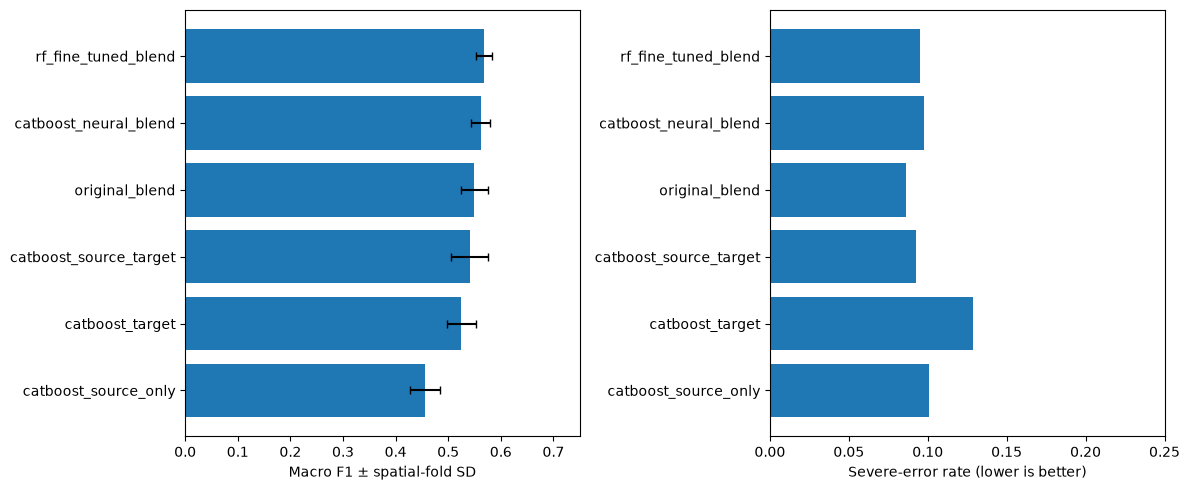

In [4]:
# Independently check the hybrid formula on every saved outer probability.
all_p = pd.read_parquet(OUT / 'predictions.parquet')
old_p = pd.read_parquet(ROOT / 'data/torch_transfer/predictions.parquet')
keys = ['fold','repetition','location_id']
cols = ['p1','p2','p3','p4']
hybrid_p = all_p.loc[all_p.method.eq('catboost_neural_blend')].set_index(keys).sort_index()
cb_p = all_p.loc[all_p.method.eq('catboost_source_target')].set_index(keys).sort_index()
nn_p = old_p.loc[old_p.method.eq('fine_tuned')].set_index(keys).sort_index()
pd.testing.assert_index_equal(hybrid_p.index,cb_p.index)
pd.testing.assert_index_equal(hybrid_p.index,nn_p.index)
np.testing.assert_allclose(hybrid_p[cols],.5*cb_p[cols]+.5*nn_p[cols],atol=1e-12)
runs = pd.read_csv(OUT / 'run_metrics.csv')
folds = runs.groupby(['method','fold'])[METRICS].mean()
summary = pd.read_csv(OUT / 'summary.csv', index_col='method')
np.testing.assert_allclose(folds.groupby('method').mean(), summary[METRICS], atol=1e-12)
np.testing.assert_allclose(folds.groupby('method').macro_f1.std(), summary.macro_f1_fold_sd, atol=1e-12)
display(summary.sort_values('macro_f1',ascending=False).round(4))
order = summary.sort_values('macro_f1')
fig, axes = plt.subplots(1,2,figsize=(12,5))
axes[0].barh(order.index,order.macro_f1,xerr=order.macro_f1_fold_sd,capsize=3)
axes[0].set(xlabel='Macro F1 ± spatial-fold SD',xlim=(0,.75))
axes[1].barh(order.index,order.severe_error_rate)
axes[1].set(xlabel='Severe-error rate (lower is better)',xlim=(0,.25))
fig.tight_layout()
fig.savefig(OUT / 'comparison.png',dpi=160)
plt.show()

In [5]:
classes = pd.read_csv(OUT / 'class_metrics.csv')
display(classes.groupby(['method','fold','age_class']).f1.mean()
        .groupby(['method','age_class']).mean().unstack('age_class').round(4))
display(pd.read_csv(OUT / 'paired_fold_scores.csv').round(5))

age_class,1,2,3,4
method,,,,
catboost_neural_blend,0.6471,0.5184,0.5615,0.5204
catboost_source_only,0.6003,0.4018,0.4169,0.4058
catboost_source_target,0.6432,0.5058,0.5351,0.4808
catboost_target,0.6419,0.5016,0.5202,0.4370
original_blend,0.6337,0.5872,0.4847,0.4919
rf_fine_tuned_blend,0.6514,0.5571,0.5437,0.5192


,fold,catboost_neural_blend,catboost_source_only,catboost_source_target,catboost_target,original_blend,rf_fine_tuned_blend,new_hybrid_minus_current
0,0,0.54065,0.42352,0.49633,0.50495,0.53277,0.56070,-0.02005
1,1,0.56771,0.49078,0.57571,0.52347,0.56334,0.56336,0.00435
2,2,0.55608,0.44296,0.53119,0.53847,0.55149,0.56196,-0.00588
3,3,0.58905,0.47987,0.57792,0.56452,0.58276,0.59583,-0.00678
4,4,0.55565,0.44396,0.52497,0.49455,0.51657,0.55750,-0.00186


## 4. Reload and predict

The exported example combines native CatBoost model files, median imputers, and the earlier fine-tuned network's state dictionary and scaler. It is a fold-0/repetition-0 demonstration, not a final model trained on a newly authorized competition sample. Prediction uses only the allowlisted feature columns.

In [6]:
target = pd.read_parquet(ROOT / 'data/preprocessed_age_labels/amsterdam_supervised_features.parquet')
example = target.loc[target.fold.eq(0)].head(8)
p = predict_example(example)
output = pd.DataFrame(dict(location_id=example.location_id.to_numpy(),
    predicted_age_class=np.arange(1,5)[p.argmax(1)],
    **{f'p{c}':p[:,i] for i,c in enumerate(range(1,5))}))
np.testing.assert_allclose(p.sum(1),1,atol=1e-6)
display(output)

,location_id,predicted_age_class,p1,p2,p3,p4
0,Amsterdam:20641:193600,4,0.045138,0.084995,0.292967,0.576901
1,Amsterdam:20641:193601,4,0.060996,0.123285,0.233963,0.581756
2,Amsterdam:20641:193603,4,0.046452,0.093106,0.385794,0.474648
3,Amsterdam:20642:193600,4,0.036237,0.059604,0.304248,0.599910
4,Amsterdam:20642:193602,4,0.050629,0.109980,0.383115,0.456275
5,Amsterdam:20642:193605,3,0.049896,0.106504,0.426352,0.417247
6,Amsterdam:20642:193606,4,0.058450,0.128176,0.401627,0.411748
7,Amsterdam:20642:193610,4,0.042962,0.093155,0.332848,0.531035


## Conclusion

The following conclusion is computed from the saved, verified results. A mean development gain is not proof of an independent-test improvement. Consider class-level and severe-error trade-offs before changing the current model.

In [7]:
current = summary.loc['rf_fine_tuned_blend','macro_f1']
new = summary.loc['catboost_neural_blend','macro_f1']
best = summary.drop(index='catboost_source_only').macro_f1.idxmax()
print(f'Current RF–neural hybrid: {current:.4f}')
print(f'CatBoost–neural hybrid: {new:.4f}; delta vs current: {new-current:+.4f}')
print(f'Highest observed adapted/control macro F1: {best} ({summary.loc[best,"macro_f1"]:.4f})')
print('These are previously used spatial development folds, not an independent test.')

Current RF–neural hybrid: 0.5679
CatBoost–neural hybrid: 0.5618; delta vs current: -0.0060
Highest observed adapted/control macro F1: rf_fine_tuned_blend (0.5679)
These are previously used spatial development folds, not an independent test.


Evaluation guidance: installed scikit-learn skill and its model-evaluation reference. API and regularization guidance: official [CatBoost parameter tuning](https://catboost.ai/docs/en/concepts/parameter-tuning) and [partial-tree probability prediction](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier_staged_predict_proba). Firecrawl developer search failed DNS resolution; official documents were retrieved using the web fallback. See the [experiment report](../../docs/CATBOOST.md).